# 01 Cleaning: Track 2, Cardiovascular Health in Women

This notebook loads each dataset, cleans it and records every rule in `team/docs/cleaning_log.md`.

**How to use it**

- Run the cells from top to bottom (**Runtime > Run all** on Colab).
- Cells marked **You decide** hold our team's choices, each explained in an **Our decision** note.
- All three datasets are cleaned here, even though Dataset 2 is used only for a signal check.

Read [`2-the-data.md`](../../2-the-data.md) first if you have not.
## Our team's cleaning decisions at a glance

| Dataset | Used for | Key decisions |
|---|---|---|
| 1. Cardiovascular Disease | **Main analysis** | Keep women **and** men (men are the comparison group). Remove double entries, physically impossible blood pressure, height, weight and BMI values. Every rule is logged with its count |
| 2. Heart Attack Risk (synthetic) | Signal check only (02, appendix) | Basic tidying. Not used for any finding |
| 3. GBD Tables S1 and S2 | Global context (02, section 7) | Fix the printed headers, split the intervals into estimate, lower and upper, standardize country names |

Each decision is explained in the cell where it is made, and `docs/cleaning_log.md` lists the number of records each rule removed.

**How to run.** Download or clone the repository, install the packages with `pip install -r track-02/team/requirements.txt`, open this notebook from `track-02/team/notebooks/` and run it top to bottom. It reads the raw data from `track-02/data/` and saves outputs to `track-02/team/` (`data_clean/`, `figures/` and `docs/cleaning_log.md`). Run `01_cleaning.ipynb` before `02_analysis.ipynb`.


In [1]:
# Setup: run this cell first. It finds the track-02 folder of this repository,
# reads the raw data from track-02/data/ and saves every output in track-02/team/.
import re, sys, subprocess
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

TEAM_REPO = "https://github.com/ankit010798verma/HeartBeat-OpenDatathon.git"   # only used on Colab
IN_COLAB = "google.colab" in sys.modules

def find_track_dir():
    """Walk up from this notebook's folder until we reach track-02."""
    here = Path.cwd().resolve()
    for folder in [here, *here.parents]:
        if folder.name == "track-02" and (folder / "data").is_dir():
            return folder
        if (folder / "track-02" / "data").is_dir():
            return folder / "track-02"
    if IN_COLAB:   # opened directly in Colab: download the repository first
        dest = Path("/content") / Path(TEAM_REPO).stem
        if not dest.exists():
            subprocess.run(["git", "clone", "--depth", "1", TEAM_REPO, str(dest)], check=True)
        return dest / "track-02"
    raise FileNotFoundError("Could not find the track-02 folder. Open this notebook from "
                            "track-02/team/notebooks/ inside the downloaded repository.")

TRACK = find_track_dir()
TEAM = TRACK / "team"
CLEAN = TEAM / "data_clean"
FIGURES = TEAM / "figures"
for folder in (CLEAN, FIGURES, TEAM / "docs"):
    folder.mkdir(parents=True, exist_ok=True)
SEARCH_DIRS = [TRACK / "data", TRACK / "data" / "gbd"]

def missing(name):
    print(f"Fill in {name} in the cell above, then rerun this cell.")

print("Track folder:", TRACK)
print("Outputs go to:", TEAM)


Track folder: HeartBeat-OpenDatathon/track-02
Outputs go to: HeartBeat-OpenDatathon/track-02/team


## Helpers

You do not need to edit this cell. `log_step` records a cleaning rule and how many records it affected.

In [2]:
LOG = []

def log_step(dataset, rule, before, after, reason=""):
    """Record one cleaning rule. before and after are row counts."""
    LOG.append({"Dataset": dataset, "Rule": rule, "Reason": reason,
                "Records before": before, "Records after": after,
                "Records affected": before - after})
    print(f"[{dataset}] {rule}: {before - after:,} records affected ({after:,} remain)")

def write_log():
    path = TEAM / "docs" / "cleaning_log.md"
    lines = ["# Cleaning Log", "", "Written by `01_cleaning.ipynb`. Rerun the notebook to update it.", "",
             "| Dataset | Rule | Reason | Records before | Records after | Records affected |",
             "|---|---|---|---|---|---|"]
    for r in LOG:
        lines.append(f"| {r['Dataset']} | {r['Rule']} | {r['Reason']} | {r['Records before']:,} | "
                     f"{r['Records after']:,} | {r['Records affected']:,} |")
    path.write_text("\n".join(lines) + "\n")
    print(f"Wrote {len(LOG)} rules to {path}")

def find_file(*names):
    """Return the first non-empty file matching any name. Empty placeholders are skipped."""
    for folder in SEARCH_DIRS:
        for name in names:
            p = folder / name
            if p.is_file() and p.stat().st_size > 0:
                return p
    return None

def load_csv(path, **kwargs):
    """Read a CSV, detecting whether it uses commas or semicolons."""
    with open(path, encoding="utf-8-sig") as f:
        first = f.readline()
    sep = ";" if first.count(";") > first.count(",") else ","
    return pd.read_csv(path, sep=sep, **kwargs)

def load_table(path, header=None):
    """Read a CSV or Excel table. header=None keeps every row so you can see the real headers."""
    if path.suffix.lower() in (".xlsx", ".xls"):
        return pd.read_excel(path, header=header)
    return load_csv(path, header=header)


---
# Dataset 1: Cardiovascular Disease Dataset

In [3]:
d1_path = find_file("cardiovascular_dataset_OpenBio_Final.csv")
if d1_path:
    d1_raw = load_csv(d1_path)
    print(f"Dataset 1: {d1_raw.shape[0]:,} rows, {d1_raw.shape[1]} columns")
    display(d1_raw.head())
else:
    d1_raw = None
    print("Dataset 1 not found or still an empty placeholder. Skip this section or add the file to track-02/data/.")


Dataset 1: 70,000 rows, 13 columns


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


### Step 1: Duplicates and age

Age is stored in days. This converts it to years.

**Our decision on duplicates.** No `id` appears twice, but the data dictionary notes 24 rows that match another row in every column except `id`. A match on age to the day plus height, weight, both blood pressures and every yes/no answer is very unlikely to happen by chance, so we treat these as double entries and keep the first copy. This rule touches about 0.03% of rows, and the sensitivity check in 02 shows that keeping them changes nothing.


In [4]:
if d1_raw is not None:
    d1 = d1_raw.copy()
    n = len(d1)
    d1 = d1.drop_duplicates(subset="id")
    log_step("D1", "Drop duplicate ids", n, len(d1), "Each patient should appear once")

    n = len(d1)
    d1 = d1[~d1.drop(columns="id").duplicated(keep="first")]
    log_step("D1", "Drop rows identical to an earlier row in every column except id", n, len(d1),
             "A match on age to the day and every measurement is very unlikely by chance, so these look like double entries (first copy kept)")
    d1["age_years"] = d1["age"] / 365.25
    print(d1["age_years"].describe().round(1))


[D1] Drop duplicate ids: 0 records affected (70,000 remain)
[D1] Drop rows identical to an earlier row in every column except id: 24 records affected (69,976 remain)
count    69976.0
mean        53.3
std          6.8
min         29.6
25%         48.4
50%         53.9
75%         58.4
max         64.9
Name: age_years, dtype: float64


### Step 2: Check the sex coding

The Kaggle page lists `gender` only as a "categorical code" and does not say which number is which. Women are shorter on average, so the code with the lower mean height is women. In this file that is code 1. If the check below disagrees, change `WOMEN_CODE`.

**You decide:** `D1_SEX_SCOPE`. Use `"women"` to keep only women, or `"both"` to compare women with men.
**Our decision:** `D1_SEX_SCOPE = "both"`. Our question asks how cardiovascular risk *differs* for women, so we need men as a comparison group. We still fit women-only models in 02, and the forest plot shows women's and men's results side by side.


In [5]:
WOMEN_CODE = 1
D1_SEX_SCOPE = "both"    # "women" or "both". We compare women with men (see the note above)

if d1_raw is not None:
    print("Mean height (cm) by gender code:")
    print(d1.groupby("gender")["height"].mean().round(1))
    d1["female"] = (d1["gender"] == WOMEN_CODE).astype(int)
    if D1_SEX_SCOPE == "women":
        n = len(d1)
        d1 = d1[d1["female"] == 1].copy()
        log_step("D1", "Keep women only", n, len(d1), "Track focus on women")
    print("\nRows by sex:", d1["female"].map({1: "women", 0: "men"}).value_counts().to_dict())


Mean height (cm) by gender code:
gender
1    161.4
2    169.9
Name: height, dtype: float64

Rows by sex: {'women': 45509, 'men': 24467}


### Step 3: Look at the measurements

Before choosing a rule, look at the values. The table shows the smallest and largest values, and the plots show where most values sit.

,ap_hi,ap_lo,height,weight
count,69976.0,69976.0,69976.0,69976.0
mean,128.8,96.6,164.4,74.2
std,154.0,188.5,8.2,14.4
min,-150.0,-70.0,55.0,10.0
0.1%,12.0,40.0,120.0,40.0
1%,90.0,60.0,147.0,48.0
50%,120.0,80.0,165.0,72.0
99%,180.0,1000.0,184.0,117.0
99.9%,220.0,1110.0,190.0,150.0
max,16020.0,11000.0,250.0,200.0


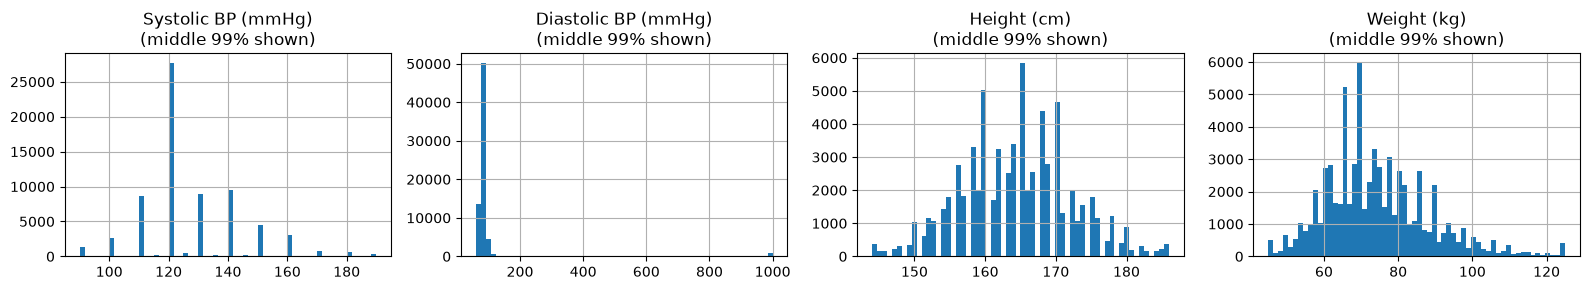

In [6]:
MEASURES = {"ap_hi": "Systolic BP (mmHg)", "ap_lo": "Diastolic BP (mmHg)",
            "height": "Height (cm)", "weight": "Weight (kg)"}

if d1_raw is not None:
    display(d1[list(MEASURES)].describe(percentiles=[0.001, 0.01, 0.5, 0.99, 0.999]).round(1))
    fig, axes = plt.subplots(1, 4, figsize=(16, 3))
    for ax, (col, label) in zip(axes, MEASURES.items()):
        lo, hi = d1[col].quantile([0.005, 0.995])
        d1[col].clip(lo, hi).hist(bins=60, ax=ax)
        ax.set_title(label + "\n(middle 99% shown)")
    plt.tight_layout()
    plt.show()


### Step 4: Plausibility rules

**You decide:** a range for each measurement, written as `(low, high)`, and a one-sentence reason. Rows outside the range are removed. Leave a range as `None` to skip it, but note that impossible values will stay in.

**Our decision.** We based each range on what is physically possible at a routine adult check-up, not on percentiles of this sample, so the rule would be the same for any similar dataset. The table above shows why a rule is needed: diastolic pressure reaches 11,000 mmHg, some pressures are negative and one adult is recorded as 55 cm tall. These are typing errors. We remove them instead of guessing a correction (for example, reading 1,100 as 110).

| Measure | Range kept | Why |
|---|---|---|
| Systolic blood pressure (`ap_hi`) | 70 to 250 mmHg | Below 70 is shock-level and would not be seen at a routine exam; above 250 is beyond recorded clinical extremes |
| Diastolic blood pressure (`ap_lo`) | 40 to 150 mmHg | Outside this range is not compatible with a seated outpatient reading; values like 1,000 look like an extra zero |
| Height | 120 to 220 cm | Adult heights outside this range are extremely rare; values like 55 cm are entry errors |
| Weight | 30 to 200 kg | Under 30 kg is implausible for an adult at a check-up; 200 kg is the file maximum and is physically possible |
| Systolic must exceed diastolic | Always | The pressure while the heart beats is always higher than the pressure between beats |

These cut-offs are judgment calls, so in 02 (section 4) we rerun the main model with **stricter** and **looser** ranges to check that our finding does not depend on them.


In [7]:
RANGES = {
    "ap_hi":  {"range": (70, 250),  "reason": "Systolic below 70 mmHg is shock-level and above 250 is beyond recorded clinical extremes; values like 16,020 or -150 are entry errors"},
    "ap_lo":  {"range": (40, 150),  "reason": "Diastolic outside 40-150 mmHg is not compatible with an outpatient reading; values like 1,000 look like an extra zero"},
    "height": {"range": (120, 220), "reason": "Adult heights outside 120-220 cm are extremely rare; values like 55 cm are entry errors"},
    "weight": {"range": (30, 200),  "reason": "Under 30 kg is implausible for an adult at a check-up; 200 kg is the file maximum and physically possible"},
}

if d1_raw is not None:
    for col, rule in RANGES.items():
        if rule["range"] is None:
            missing(f'RANGES["{col}"]')
            continue
        lo, hi = rule["range"]
        n = len(d1)
        d1 = d1[d1[col].between(lo, hi)]
        log_step("D1", f"Keep {col} between {lo} and {hi}", n, len(d1), rule["reason"])

    n = len(d1)
    d1 = d1[d1["ap_hi"] > d1["ap_lo"]]
    log_step("D1", "Keep rows where systolic > diastolic", n, len(d1), "Systolic is always higher than diastolic")


[D1] Keep ap_hi between 70 and 250: 229 records affected (69,747 remain)
[D1] Keep ap_lo between 40 and 150: 1,017 records affected (68,730 remain)
[D1] Keep height between 120 and 220: 50 records affected (68,680 remain)
[D1] Keep weight between 30 and 200: 6 records affected (68,674 remain)
[D1] Keep rows where systolic > diastolic: 88 records affected (68,586 remain)


### Step 5: BMI and ordered categories

BMI is calculated after cleaning height and weight. Cholesterol and glucose become ordered labels so plots and models keep their order.

**Our extra rule: BMI between 14 and 60.** A height and a weight can each pass their own range but combine into an impossible body, such as 200 cm and 40 kg (BMI 10). A BMI below 14 is life-threatening starvation and above 60 is extremely rare, so we treat combinations outside 14 to 60 as entry errors.


In [8]:
LEVELS = {1: "normal", 2: "above normal", 3: "well above normal"}

if d1_raw is not None:
    d1["bmi"] = d1["weight"] / (d1["height"] / 100) ** 2
    n = len(d1)
    d1 = d1[d1["bmi"].between(14, 60)].copy()
    log_step("D1", "Keep BMI between 14 and 60", n, len(d1),
             "Height and weight can each look plausible but combine into an impossible body; BMI under 14 or over 60 is treated as an entry error")
    for col in ("cholesterol", "gluc"):
        d1[col + "_level"] = pd.Categorical(d1[col].map(LEVELS), categories=list(LEVELS.values()), ordered=True)
    display(d1[["age_years", "bmi", "ap_hi", "ap_lo"]].describe().round(1))
    print(d1["cholesterol_level"].value_counts().sort_index())
    d1.to_csv(CLEAN / "d1_clean.csv", index=False)
    print(f"Saved {len(d1):,} rows to {CLEAN / 'd1_clean.csv'}")


[D1] Keep BMI between 14 and 60: 29 records affected (68,557 remain)


,age_years,bmi,ap_hi,ap_lo
count,68557.0,68557.0,68557.0,68557.0
mean,53.3,27.4,126.7,81.3
std,6.8,5.2,16.7,9.4
min,29.6,14.5,70.0,40.0
25%,48.3,23.9,120.0,80.0
50%,53.9,26.3,120.0,80.0
75%,58.4,30.1,140.0,90.0
max,64.9,59.5,240.0,150.0


cholesterol_level
normal               51404
above normal          9290
well above normal     7863
Name: count, dtype: int64
Saved 68,557 rows to HeartBeat-OpenDatathon/track-02/team/data_clean/d1_clean.csv


### Step 6: Did the rows we removed look different?

Removing rows can bias a result if the removed rows are systematically different, for example if they were more often people with heart disease. This check compares the removed rows with the kept rows. A small difference is expected.


In [9]:
if d1_raw is not None:
    removed = d1_raw[~d1_raw["id"].isin(d1["id"])]
    kept = d1
    comparison = pd.DataFrame({
        "Rows": [len(kept), len(removed)],
        "Share with CVD (%)": [100 * kept["cardio"].mean(), 100 * removed["cardio"].mean()],
        "Share women (%)": [100 * (kept["gender"] == WOMEN_CODE).mean(), 100 * (removed["gender"] == WOMEN_CODE).mean()],
        "Mean age (years)": [kept["age"].mean() / 365.25, removed["age"].mean() / 365.25],
    }, index=["Kept", "Removed"]).round(1)
    display(comparison)
    print(f"We removed {len(removed):,} of {len(d1_raw):,} rows ({100 * len(removed) / len(d1_raw):.1f}%).")


,Rows,Share with CVD (%),Share women (%),Mean age (years)
Kept,68557,49.5,65.1,53.3
Removed,1443,73.5,61.1,53.9


We removed 1,443 of 70,000 rows (2.1%).


**What we found.** We removed about 2% of rows, but those rows were much more likely to have CVD (about 74%, against about 50% in the rows we kept). Most of them are blood pressure typos such as a diastolic reading of 1,000, and a typo like that most likely hides a high real reading (100 mmHg). So our cleaning slightly under-represents people with high blood pressure and CVD. We report this as a limitation, and in 02 (section 4) we test it directly: one sensitivity check rescues obvious extra-zero typos (1,000 becomes 100) instead of removing them, and another uses looser ranges.


---
# Dataset 2: Heart Attack Risk Prediction Dataset (synthetic)

Column names are converted to lowercase with underscores, so `Heart Attack Risk` becomes `heart_attack_risk`. This makes them easier to use in models.

In [10]:
d2_path = find_file("heart_attack_prediction_dataset_OpenBio_Final.csv")
if d2_path:
    d2_raw = load_csv(d2_path)
    print(f"Dataset 2: {d2_raw.shape[0]:,} rows, {d2_raw.shape[1]} columns")
    display(d2_raw.head())
else:
    d2_raw = None
    print("Dataset 2 not found or still an empty placeholder. Skip this section or add the file to track-02/data/.")


Dataset 2: 8,763 rows, 26 columns


,Patient ID,Age,Sex,Cholesterol,Blood Pressure,Heart Rate,Diabetes,Family History,Smoking,Obesity,...,Sedentary Hours Per Day,Income,BMI,Triglycerides,Physical Activity Days Per Week,Sleep Hours Per Day,Country,Continent,Hemisphere,Heart Attack Risk
0,BMW7812,67,Male,208,158/88,72,0,0,1,0,...,6.615001,261404,31.251233,286,0,6,Argentina,South America,Southern Hemisphere,0
1,CZE1114,21,Male,389,165/93,98,1,1,1,1,...,4.963459,285768,27.194973,235,1,7,Canada,North America,Northern Hemisphere,0
2,BNI9906,21,Female,324,174/99,72,1,0,0,0,...,9.463426,235282,28.176571,587,4,4,France,Europe,Northern Hemisphere,0
3,JLN3497,84,Male,383,163/100,73,1,1,1,0,...,7.648981,125640,36.464704,378,3,4,Canada,North America,Northern Hemisphere,0
4,GFO8847,66,Male,318,91/88,93,1,1,1,1,...,1.514821,160555,21.809144,231,1,5,Thailand,Asia,Northern Hemisphere,0


### Step 1: Rename columns and split blood pressure

`Blood Pressure` is text such as `158/88`. This splits it into two number columns.

In [11]:
def snake(name):
    return re.sub(r"[^0-9a-z]+", "_", name.strip().lower()).strip("_")

if d2_raw is not None:
    d2 = d2_raw.rename(columns=snake).copy()
    n = len(d2)
    d2 = d2.drop_duplicates(subset="patient_id")
    log_step("D2", "Drop duplicate patient ids", n, len(d2), "Each record should appear once")

    bp = d2["blood_pressure"].astype(str).str.extract(r"^\s*(\d+)\s*/\s*(\d+)\s*$").astype(float)
    d2["bp_systolic"], d2["bp_diastolic"] = bp[0], bp[1]
    n = len(d2)
    d2 = d2.dropna(subset=["bp_systolic", "bp_diastolic"])
    log_step("D2", "Drop rows where blood pressure is not in 'number/number' form", n, len(d2), "Cannot be split")
    display(d2[["blood_pressure", "bp_systolic", "bp_diastolic"]].head())


[D2] Drop duplicate patient ids: 0 records affected (8,763 remain)
[D2] Drop rows where blood pressure is not in 'number/number' form: 0 records affected (8,763 remain)


,blood_pressure,bp_systolic,bp_diastolic
0,158/88,158.0,88.0
1,165/93,165.0,93.0
2,174/99,174.0,99.0
3,163/100,163.0,100.0
4,91/88,91.0,88.0


### Step 2: Encode yes/no and ordered levels

In this file the yes/no columns already hold 1 and 0. That includes Alcohol Consumption: the Kaggle page describes it as levels, but the file stores only 0 or 1. Diet is text and keeps its order: Unhealthy, Average, Healthy. Sex becomes a `female` column (1 or 0). Any value the notebook does not recognize is printed so you can decide what to do.

In [12]:
YES_NO = {"yes": 1, "no": 0, "1": 1, "0": 0, "true": 1, "false": 0}
BINARY = ["diabetes", "family_history", "smoking", "obesity", "previous_heart_problems",
          "medication_use", "heart_attack_risk"]
ALCOHOL_ORDER = ["None", "Light", "Moderate", "Heavy"]
DIET_ORDER = ["Unhealthy", "Average", "Healthy"]

if d2_raw is not None:
    for col in BINARY:
        if col not in d2:
            continue
        mapped = d2[col].astype(str).str.strip().str.lower().map(YES_NO)
        bad = d2.loc[mapped.isna(), col].unique()
        if len(bad):
            print(f"{col}: unrecognized values {list(bad)[:5]}")
        d2[col] = mapped

    alc = d2["alcohol_consumption"].astype(str).str.strip()
    if alc.str.title().isin(ALCOHOL_ORDER).all():
        d2["alcohol_level"] = pd.Categorical(alc.str.title(), categories=ALCOHOL_ORDER, ordered=True)
        d2["alcohol_code"] = d2["alcohol_level"].cat.codes
        print("Alcohol is stored as levels:", ALCOHOL_ORDER)
    else:
        d2["alcohol_consumption"] = alc.str.lower().map(YES_NO)
        print("Alcohol is stored as yes/no, encoded as 1/0")

    d2["diet_level"] = pd.Categorical(d2["diet"].str.strip().str.title(), categories=DIET_ORDER, ordered=True)
    d2["diet_code"] = d2["diet_level"].cat.codes
    d2["female"] = (d2["sex"].str.strip().str.lower() == "female").astype(int)
    print(d2["diet_level"].value_counts().sort_index())


Alcohol is stored as yes/no, encoded as 1/0
diet_level
Unhealthy    2891
Average      2912
Healthy      2960
Name: count, dtype: int64


### Step 3: Choose who to analyze

**You decide:** `SEX_SCOPE`. Use `"women"` to keep only women, or `"both"` to compare women with men (use the `female` column as a predictor). Write the reason.
**Our decision:** keep both sexes. We do **not** use Dataset 2 for any finding. The appendix of 02 shows that no model, simple or flexible, predicts its outcome better than a coin flip, which fits the Kaggle page's note that the records were generated by ChatGPT. We keep a tidy copy only for that check.


In [13]:
SEX_SCOPE = "both"      # "women" or "both"
SEX_SCOPE_REASON = "Used only for a signal check in 02; not used for findings"

if d2_raw is not None:
    print(d2["sex"].value_counts())
    if SEX_SCOPE is None:
        missing("SEX_SCOPE")
        print("Saving both sexes for now.")
    elif SEX_SCOPE == "women":
        n = len(d2)
        d2 = d2[d2["female"] == 1]
        log_step("D2", "Keep women only", n, len(d2), SEX_SCOPE_REASON)
    d2.to_csv(CLEAN / "d2_clean.csv", index=False)
    print(f"Saved {len(d2):,} rows to {CLEAN / 'd2_clean.csv'}")


sex
Male      6111
Female    2652
Name: count, dtype: int64
Saved 8,763 rows to HeartBeat-OpenDatathon/track-02/team/data_clean/d2_clean.csv


---
# Dataset 3: Global CVD in Women (Tables S1 and S2)

These tables are copied cell for cell from the article's supplement, so they still look like printed tables:

- The first row of each file is the table title.
- Table S2 spreads its header over two rows, with `1990` and `2019` sitting above the column names, and has empty spacer columns.
- Table S1 has label rows with no numbers (`Socio-demographic index`, `GBD regions`) and a footnote in the last row.
- Estimates and their intervals share one cell, such as `1083.58 (1011.93, 1164.76)`.

The steps are:

1. Look at the raw rows and find the real header row or rows.
2. Split intervals stored as text into three numbers.
3. Standardize country names.
4. Reshape from wide to long if you need one row per year.

In [14]:
s1_path = find_file("gbd/table_s1.xlsx", "gbd/table_s1.csv", "table_s1.xlsx", "table_s1.csv")
s2_path = find_file("gbd/table_s2.xlsx", "gbd/table_s2.csv", "table_s2.xlsx", "table_s2.csv")
s1_raw = load_table(s1_path) if s1_path else None
s2_raw = load_table(s2_path) if s2_path else None
for name, raw in (("S1", s1_raw), ("S2", s2_raw)):
    if raw is None:
        print(f"Table {name} not found. Add it to track-02/data/gbd/ as table_{name.lower()}.xlsx or .csv")
    else:
        print(f"Table {name}: {raw.shape[0]} raw rows, {raw.shape[1]} raw columns. First 8 and last 2 rows (row numbers on the left):")
        display(pd.concat([raw.head(8), raw.tail(2)]))

Table S1: 32 raw rows, 3 raw columns. First 8 and last 2 rows (row numbers on the left):


,0,1,2
0,Table S1. The Mortality-to-Incidence Ratio (MI...,NaN,NaN
1,NaN,"MIR per 100,000 in 1990","MIR per 100,000 in 2019"
2,Global Female,0.42,0.32
3,Socio-demographic index,NaN,NaN
4,Low,0.49,0.43
5,Low-middle,0.48,0.38
6,Middle,0.50,0.37
7,High-middle,0.46,0.33
30,Western Sub-Saharan Africa,0.55,0.46
31,GBD: Global Burden of Disease; SDI: socio-demo...,NaN,NaN


Table S2: 207 raw rows, 11 raw columns. First 8 and last 2 rows (row numbers on the left):


,0,1,2,3,4,5,6,7,8,9,10
0,Table S2. The SDI value of 204 countries and t...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Region,1990,NaN,NaN,2019,NaN,NaN,1990-2019,NaN,NaN,SDI value in 2019
2,NaN,Incident cases No. (95% UI),"ASIR per 100, 000 No. (95% UI)",NaN,Incident cases No. (95% UI),"ASIR per 100, 000 No. (95% UI)",NaN,Percentage change of incident cases (%),EAPC (95% CI),NaN,NaN
3,Afghanistan,"37223.4 (34624.49, 39944.22)","1083.58 (1011.93, 1164.76)",NaN,"76706.62 (71482.86, 81930.32)","1046.52 (977.77, 1119.83)",NaN,106.07,"-0.25 (-0.31, -0.2)",NaN,0.343
4,Albania,"7370.5 (6929.55, 7849.77)","650.01 (610.6, 691.55)",NaN,"13283.89 (12431.19, 14190.72)","624.32 (586.86, 663.92)",NaN,80.23,"-0.13 (-0.15, -0.12)",NaN,0.681
5,Algeria,"62208.95 (57785.72, 66924.78)","1054.04 (985.59, 1128.97)",NaN,"145088.97 (135292.53, 155506.86)","938.83 (880.91, 1005.84)",NaN,133.23,"-0.48 (-0.52, -0.44)",NaN,0.652
6,American Samoa,"80.25 (75, 86.12)","626 (588.17, 665.31)",NaN,"168.99 (158.84, 180.06)","684.16 (642.27, 729.32)",NaN,110.58,"0.29 (0.26, 0.33)",NaN,0.712
7,Andorra,"142.69 (131.36, 154.68)","539.58 (497.61, 582.02)",NaN,"294.81 (273.64, 317.42)","432 (401.72, 466.27)",NaN,106.61,"-0.91 (-1.03, -0.8)",NaN,0.894
205,Zambia,"12440.6 (11083.03, 13973.11)","596.03 (556.66, 641.55)",NaN,"27867.08 (24925.52, 31081.88)","551.19 (513.06, 592.43)",NaN,124,"-0.39 (-0.43, -0.35)",NaN,0.505
206,Zimbabwe,"16524.06 (14995.96, 18341.3)","596.65 (555.31, 640.77)",NaN,"31253.08 (28772.28, 33952.18)","665.89 (620.99, 712.74)",NaN,89.14,"0.47 (0.37, 0.57)",NaN,0.476


### Step 1: Set the header row

**You decide:** the row number (left column above) that holds the real column names. Rows above it are dropped. If the header is spread over two rows, give both in a list such as `[1, 2]` and they are joined into one name per column.

What the cell does once you fill it in:

- Names become lowercase with underscores, so `MIR per 100,000 in 1990` becomes `mir_per_100_000_in_1990`. With a two-row header the lower row comes first, so `1990` above `EAPC (95% CI)` becomes `eapc_95_ci_1990`.
- Empty spacer columns are dropped. A column with no header is named by its position, such as `column_0`.
- Spaces around values are trimmed, and columns that hold only plain numbers become numbers.
- The column names are printed. Use `S1_RENAME` or `S2_RENAME` to shorten any of them.

**You decide (Table S1):** `S1_LABEL_ROWS`. Rows that have a label but no numbers are section headings or footnotes. Use `"section"` to move each label into a new `section` column for the rows under it, or `"keep"` to leave the rows as they are.
**Our decisions.** The raw preview shows that Table S1's column names are in row 1 (row 0 is the title). Table S2's names are split across rows 1 and 2 (the year on top, the measure below), so we pass `[1, 2]`. We shorten the long printed names, for example `asir_per_100_000_no_95_ui_2019` becomes `asir_2019`. In Table S1 the rows `Socio-demographic index` and `GBD regions` are headings, so we move them into a `section` column; the footnote row goes the same way.


In [15]:
S1_HEADER_ROW = 1        # row 0 is the title; row 1 holds the column names
S2_HEADER_ROW = [1, 2]   # two-row header: year on top, measure below
S1_RENAME = {"column_0": "region", "mir_per_100_000_in_1990": "mir_1990", "mir_per_100_000_in_2019": "mir_2019"}
S2_RENAME = {
    "region": "country",
    "incident_cases_no_95_ui_1990": "cases_1990",
    "asir_per_100_000_no_95_ui_1990": "asir_1990",
    "incident_cases_no_95_ui_2019": "cases_2019",
    "asir_per_100_000_no_95_ui_2019": "asir_2019",
    "percentage_change_of_incident_cases_1990_2019": "pct_change_cases",
    "eapc_95_ci_1990_2019": "eapc",
    "sdi_value_in_2019": "sdi_2019",
}
S1_LABEL_ROWS = "section"   # move the heading rows into a section column
S2_LABEL_ROWS = None   # only needed if the cell reports label rows in Table S2

def tidy_name(text):
    return re.sub(r"[^0-9a-z]+", "_", str(text).strip().lower()).strip("_")

def apply_header(raw, rows, name, rename=None):
    if raw is None:
        return None
    if rows is None:
        missing(f"{name}_HEADER_ROW")
        return None
    rows = [rows] if isinstance(rows, int) else list(rows)
    table = raw.iloc[max(rows) + 1:]
    keep = table.notna().any()                        # drop empty spacer columns
    table = table.loc[:, keep].copy()
    header = raw.loc[rows, keep].astype(object)
    upper = header.iloc[:-1].ffill(axis=1)            # a merged header cell covers the columns to its right
    names = []
    for i, col in enumerate(header.columns):
        parts = [header.iloc[-1][col]] + [upper.loc[r, col] for r in reversed(upper.index)]
        parts = [tidy_name(p) for p in parts if pd.notna(p)]
        names.append("_".join(p for p in dict.fromkeys(parts) if p) or f"column_{i}")
    if len(set(names)) < len(names):
        print(f"{name}: some column names repeat. The header may span two rows: try a list such as [{rows[0] - 1}, {rows[0]}].")
        seen = {}
        for i, n in enumerate(names):
            seen[n] = seen.get(n, 0) + 1
            if seen[n] > 1:
                names[i] = f"{n}_{seen[n]}"
    table.columns = names
    table = table.dropna(how="all").reset_index(drop=True)
    for col in table.columns:
        table[col] = table[col].map(lambda v: v.strip() if isinstance(v, str) else v)
        numbers = pd.to_numeric(table[col], errors="coerce")
        if numbers.notna().sum() == table[col].notna().sum() and numbers.notna().any():
            table[col] = numbers
    if rename:
        table = table.rename(columns=rename)
    print(f"{name}: {len(table)} rows. Columns: {list(table.columns)}")
    return table

def handle_label_rows(table, choice, name):
    """Rows with a label in the first column and nothing else are section headings or footnotes."""
    if table is None:
        return None
    is_label = table.iloc[:, 0].notna() & table.iloc[:, 1:].isna().all(axis=1)
    if not is_label.any():
        return table
    print(f"{name}: {int(is_label.sum())} rows have a label but no values: {table.loc[is_label].iloc[:, 0].tolist()}")
    if choice is None:
        missing(f"{name}_LABEL_ROWS")
    elif choice == "section":
        n = len(table)
        table["section"] = table.iloc[:, 0].where(is_label).ffill()
        table = table[~is_label].reset_index(drop=True)
        log_step(name, "Move label rows into a section column", n, len(table),
                 "Section headings and footnotes are not data rows")
    return table

s1 = handle_label_rows(apply_header(s1_raw, S1_HEADER_ROW, "S1", S1_RENAME), S1_LABEL_ROWS, "S1")
s2 = handle_label_rows(apply_header(s2_raw, S2_HEADER_ROW, "S2", S2_RENAME), S2_LABEL_ROWS, "S2")

S1: 30 rows. Columns: ['region', 'mir_1990', 'mir_2019']
S1: 3 rows have a label but no values: ['Socio-demographic index', 'GBD regions', 'GBD: Global Burden of Disease; SDI: socio-demographic index;']
[S1] Move label rows into a section column: 3 records affected (27 remain)
S2: 204 rows. Columns: ['country', 'cases_1990', 'asir_1990', 'cases_2019', 'asir_2019', 'pct_change_cases', 'eapc', 'sdi_2019']


### Step 2: Split confidence intervals

Values such as `1083.58 (1011.93, 1164.76)` become three columns: `_est`, `_low` and `_high`. The function handles commas, "to", dashes and the minus sign.

**You decide:** which columns hold values with intervals. Use the column names printed in Step 1. Table S1 has no intervals, so its list starts empty.

In [16]:
def split_ci(text):
    """'1083.58 (1011.93, 1164.76)' -> (1083.58, 1011.93, 1164.76)."""
    if pd.isna(text):
        return (np.nan, np.nan, np.nan)
    s = str(text).replace("\u2212", "-")                  # unicode minus
    s = re.sub(r"(?<=\d),(?=\d{3}\b)", "", s)            # thousands separators
    nums = [float(x) for x in re.findall(r"(?<![\d.])-?\d+(?:\.\d+)?", s)]
    if len(nums) >= 3:
        return tuple(nums[:3])
    if len(nums) == 1:
        return (nums[0], np.nan, np.nan)
    return (np.nan, np.nan, np.nan)

# Quick check
for example in ["1083.58 (1011.93, 1164.76)", "-0.25 (-0.31, -0.2)", "963.95 (850.1 to 1080.2)",
                "-0.52 (\u22120.61, \u22120.43)", "1,234,567 (1,100,000-1,300,000)"]:
    print(example, "->", split_ci(example))

S1_CI_COLUMNS = []     # Table S1 has no intervals
S2_CI_COLUMNS = ["cases_1990", "asir_1990", "cases_2019", "asir_2019", "eapc"]   # every column stored as "estimate (low, high)"

def split_columns(table, cols, name):
    if table is None:
        return
    if cols is None:
        missing(f"{name}_CI_COLUMNS")
        return
    for col in cols:
        if col not in table.columns:
            print(f"{name}: no column called {col!r}. Columns are {list(table.columns)}")
            continue
        parts = table[col].apply(split_ci)
        table[col + "_est"] = [p[0] for p in parts]
        table[col + "_low"] = [p[1] for p in parts]
        table[col + "_high"] = [p[2] for p in parts]
        print(f"{name} {col}: {table[col + '_est'].isna().sum()} values could not be read")

split_columns(s1, S1_CI_COLUMNS, "S1")
split_columns(s2, S2_CI_COLUMNS, "S2")

1083.58 (1011.93, 1164.76) -> (1083.58, 1011.93, 1164.76)
-0.25 (-0.31, -0.2) -> (-0.25, -0.31, -0.2)
963.95 (850.1 to 1080.2) -> (963.95, 850.1, 1080.2)
-0.52 (−0.61, −0.43) -> (-0.52, -0.61, -0.43)
1,234,567 (1,100,000-1,300,000) -> (1234567.0, 1100000.0, 1300000.0)
S2 cases_1990: 0 values could not be read
S2 asir_1990: 0 values could not be read
S2 cases_2019: 0 values could not be read
S2 asir_2019: 0 values could not be read
S2 eapc: 0 values could not be read


### Step 3: Standardize country names

Different sources spell countries differently. Table S2 uses the long GBD names, such as `United States of America` and `Viet Nam`, while Dataset 2 uses `United States` and `Vietnam`. This trims spaces, removes footnote marks and maps common long names to short ones. Add to `COUNTRY_FIXES` if you combine sources.

**You decide:** the column that holds country names. In Table S2 its printed header is `Region`.

In [17]:
COUNTRY_FIXES = {
    "United States of America": "United States",
    "Russian Federation": "Russia",
    "Viet Nam": "Vietnam",
    "Iran (Islamic Republic of)": "Iran",
    "Republic of Korea": "South Korea",
    "Democratic People's Republic of Korea": "North Korea",
    "Bolivia (Plurinational State of)": "Bolivia",
    "Venezuela (Bolivarian Republic of)": "Venezuela",
    "United Republic of Tanzania": "Tanzania",
    "Lao People's Democratic Republic": "Laos",
    "Syrian Arab Republic": "Syria",
    "Republic of Moldova": "Moldova",
    "Micronesia (Federated States of)": "Micronesia",
    "Taiwan (Province of China)": "Taiwan",
    "T\u00fcrkiye": "Turkey",
    "C\u00f4te d'Ivoire": "Cote d'Ivoire",
}

def clean_country(name):
    if pd.isna(name):
        return name
    s = re.sub(r"\s+", " ", str(name)).strip()
    s = re.sub(r"[\*\u2020\u2021]+$|\s*\[\d+\]$", "", s).strip()   # footnote marks
    return COUNTRY_FIXES.get(s, s)

S2_COUNTRY_COLUMN = "country"   # renamed from the printed header "Region"

if s2 is not None:
    if S2_COUNTRY_COLUMN is None:
        missing("S2_COUNTRY_COLUMN")
    else:
        before = s2[S2_COUNTRY_COLUMN].nunique()
        s2[S2_COUNTRY_COLUMN] = s2[S2_COUNTRY_COLUMN].map(clean_country)
        print(f"{before} names before, {s2[S2_COUNTRY_COLUMN].nunique()} after")

204 names before, 204 after


### Step 4: Reshape wide to long (optional)

Wide tables have one column per year, such as an ASIR column for 1990 and another for 2019. Long tables have one row per country and year, which is easier to plot.

**You decide:** the columns that identify a row (`ID_COLUMNS`) and the columns to stack (`VALUE_COLUMNS`). The year is read from each column name, so every stacked column needs a year in its name.

In [18]:
S2_ID_COLUMNS = ["country", "sdi_2019"]
S2_VALUE_COLUMNS = ["asir_1990_est", "asir_2019_est"]   # one row per country and year

s2_long = None
if s2 is not None:
    if S2_ID_COLUMNS is None or S2_VALUE_COLUMNS is None:
        missing("S2_ID_COLUMNS and S2_VALUE_COLUMNS")
    else:
        s2_long = s2.melt(id_vars=S2_ID_COLUMNS, value_vars=S2_VALUE_COLUMNS,
                          var_name="measure", value_name="value")
        s2_long["year"] = s2_long["measure"].str.extract(r"((?:19|20)\d{2})")[0].astype(int)
        s2_long["measure"] = s2_long["measure"].str.replace(r"_?(?:19|20)\d{2}", "", regex=True).str.strip("_")
        display(s2_long.head())

for name, table in (("s1", s1), ("s2", s2), ("s2_long", s2_long)):
    if table is not None:
        table.to_csv(CLEAN / f"{name}_clean.csv", index=False)
        print(f"Saved {name}_clean.csv ({len(table)} rows)")

,country,sdi_2019,measure,value,year
0,Afghanistan,0.343,asir_est,1083.58,1990
1,Albania,0.681,asir_est,650.01,1990
2,Algeria,0.652,asir_est,1054.04,1990
3,American Samoa,0.712,asir_est,626.00,1990
4,Andorra,0.894,asir_est,539.58,1990


Saved s1_clean.csv (27 rows)
Saved s2_clean.csv (204 rows)
Saved s2_long_clean.csv (408 rows)


---
# Write the Cleaning Log

Run this last. Open `team/docs/cleaning_log.md` afterwards and check that each rule has a reason.

In [19]:
write_log()
display(pd.DataFrame(LOG))


Wrote 11 rules to HeartBeat-OpenDatathon/track-02/team/docs/cleaning_log.md


,Dataset,Rule,Reason,Records before,Records after,Records affected
0,D1,Drop duplicate ids,Each patient should appear once,70000,70000,0
1,D1,Drop rows identical to an earlier row in every...,A match on age to the day and every measuremen...,70000,69976,24
2,D1,Keep ap_hi between 70 and 250,Systolic below 70 mmHg is shock-level and abov...,69976,69747,229
3,D1,Keep ap_lo between 40 and 150,Diastolic outside 40-150 mmHg is not compatibl...,69747,68730,1017
4,D1,Keep height between 120 and 220,Adult heights outside 120-220 cm are extremely...,68730,68680,50
5,D1,Keep weight between 30 and 200,Under 30 kg is implausible for an adult at a c...,68680,68674,6
6,D1,Keep rows where systolic > diastolic,Systolic is always higher than diastolic,68674,68586,88
7,D1,Keep BMI between 14 and 60,Height and weight can each look plausible but ...,68586,68557,29
8,D2,Drop duplicate patient ids,Each record should appear once,8763,8763,0
9,D2,Drop rows where blood pressure is not in 'numb...,Cannot be split,8763,8763,0
